# Live SerialAnalysis signals
Run the install and setup cells, then use the receive check below to inspect raw serial bytes. Run the live graph cell separately. Each opens the port, so interrupt one before starting the other.


In [7]:
%pip install pyserial matplotlib

Note: you may need to restart the kernel to use updated packages.


In [6]:
from pathlib import Path
import sys
import time

# Allow launch from the repository root or the Live folder.
cwd = Path.cwd().resolve()
repo = cwd if (cwd / "SerialAnalysis" / "Live").is_dir() else cwd.parents[1]
if not (repo / "SerialAnalysis" / "Live").is_dir():
    raise RuntimeError("Start Jupyter from the repository root or SerialAnalysis/Live")
sys.path.insert(0, str(repo))

from IPython.display import display
from matplotlib import pyplot as plt
# Reload local code when rerunning setup after an edit.
import importlib
recorder_module = importlib.reload(importlib.import_module("SerialAnalysis.Live.recorder"))
plot_module = importlib.reload(importlib.import_module("SerialAnalysis.Live.live_plot"))
LiveRecorder = recorder_module.LiveRecorder
LivePlot = plot_module.LivePlot
run_jupyter_live_plot = plot_module.run_jupyter_live_plot
print(f"Loaded recorder from {recorder_module.__file__}")

PORT = "COM8"
OUTPUT = repo / "sessions"
DURATION_MIN = 30
WINDOW_S = 5
REFRESH_S = 0.2


Loaded recorder from C:\Users\asher\projects\ece198\SerialAnalysis\Live\recorder.py


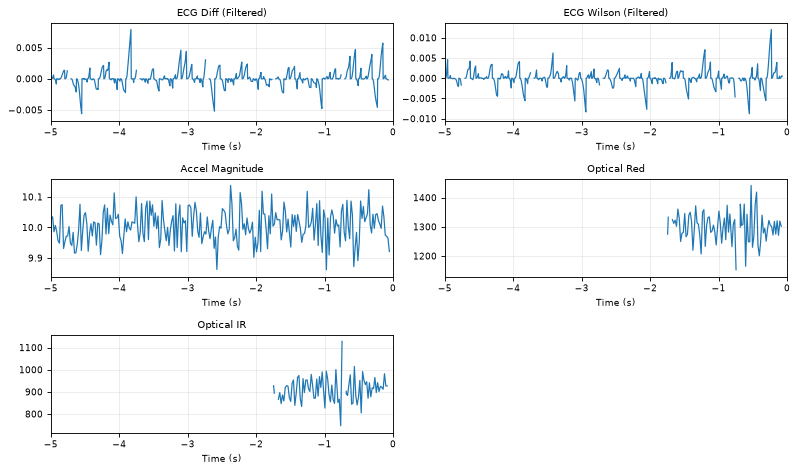

In [ ]:
if "recorder" in globals() and recorder is not None:
    recorder.close()
recorder = LiveRecorder(PORT, OUTPUT, DURATION_MIN, window_s=WINDOW_S)

plot = LivePlot(
    channels=["diff_filtered", "wilson_filtered", "accel_magnitude", "red", "infrared"],
    window_s=5.0,
    figsize=(10.0, 6.0),
    dpi=80,
)
handle = display(plot.figure, display_id=True)

with recorder:
    run_jupyter_live_plot(recorder, plot, handle, refresh_s=REFRESH_S)

In [11]:
with LiveRecorder(PORT, OUTPUT, DURATION_MIN, window_s=WINDOW_S) as recorder:
    plot = LivePlot(WINDOW_S)
    handle = display(plot.figure, display_id=True)
    print(f"Recording to {recorder.session_dir}; interrupt this cell to stop.")
    last_refresh = 0.0
    try:
        while not recorder.done:
            recorder.poll()
            now = time.monotonic()
            if now - last_refresh >= REFRESH_S:
                plot.update(recorder)
                handle.update(plot.figure)
                last_refresh = now
    except KeyboardInterrupt:
        pass
    finally:
        plot.update(recorder)
        handle.update(plot.figure)
        plt.close(plot.figure)
        print(f"Finished: {recorder.session_dir}")


TypeError: 'int' object is not iterable

In [12]:
# Diagnostic: print incoming binary chunks and decoded frames for 10 seconds.
# Run this cell while the live graph cell is stopped.
from SerialAnalysis.Live.recorder import open_serial
from SerialAnalysis.Live.protocol import Decoder

MONITOR_SECONDS = 10
decoder = Decoder()
port = open_serial(PORT)
start = last_wait = time.monotonic()
received_bytes = received_frames = 0
print(f"Listening on {PORT} at {port.baudrate} baud, DTR={port.dtr}, for {MONITOR_SECONDS} seconds...", flush=True)
try:
    while time.monotonic() - start < MONITOR_SECONDS:
        chunk = port.read(1024)
        if chunk:
            received_bytes += len(chunk)
            print(f"RX {len(chunk)} bytes: {chunk.hex(' ')}", flush=True)
            frames = decoder.feed(chunk)
            received_frames += len(frames)
            for frame in frames:
                print(f"  frame type={frame.type} seq={frame.sequence} "
                      f"board_us={frame.timestamp_us} samples={frame.count}", flush=True)
        elif time.monotonic() - last_wait >= 1:
            print("Waiting for serial bytes...", flush=True)
            last_wait = time.monotonic()
except KeyboardInterrupt:
    print("Receive check interrupted.", flush=True)
finally:
    port.close()
    print(f"Closed {PORT}: {received_bytes} bytes, {received_frames} frames, "
          f"{decoder.bad} bad CRC/lengthframes.", flush=True)


Listening on COM8 at 115200 baud, DTR=True, for 10 seconds...
RX 108 bytes: a5 5a 03 0a 03 e3 ed 11 04 04 30 00 e3 ed 11 04 26 03 00 00 4a 03 00 00 f3 14 12 04 d7 03 00 00 c3 02 00 00 12 79 13 04 72 04 00 00 77 03 00 00 f3 14 12 04 e6 03 00 00 ff 02 00 00 24 59 a5 5a 01 0b 03 f2 c6 11 04 08 20 00 d2 0f 8e 0c d4 0f 8f 0c e9 0f 95 0c cf 0f 95 0c d1 0f 91 0c d1 0f 90 0c f2 0f 8e 0c d4 0f 90 0c ea 8f
  frame type=3 seq=778 board_us=68283875 samples=4
  frame type=1 seq=779 board_us=68273906 samples=8
RX 108 bytes: a5 5a 03 0c 03 9c 00 15 04 04 30 00 9c 00 15 04 5e 03 00 00 a9 02 00 00 ac 27 15 04 fe 03 00 00 e1 02 00 00 d1 88 16 04 24 04 00 00 92 03 00 00 ac 27 15 04 9d 03 00 00 fa 02 00 00 75 0f a5 5a 01 0d 03 f0 dc 14 04 08 20 00 d3 0f 91 0c d1 0f 90 0c ec 0f 92 0c d3 0f 8f 0c d3 0f 8d 0c d1 0f 90 0c dd 0f 91 0c d4 0f 8e 0c 79 bc
  frame type=3 seq=780 board_us=68485276 samples=4
  frame type=1 seq=781 board_us=68476144 samples=8
RX 152 bytes: a5 5a 03 0e 03 c4 11 18 04 04 30 00 c4 11 18